# Football Player Match Rating — EDA & CatBoost Regression

**Dataset:** `football_player_rating_dataset.csv`  
**Target:** `player_rating` (`float64`)  
**Unit of observation:** one player's performance in one match  
**Problem type:** supervised regression

## Objective
1. Audit all 63 columns before making modeling conclusions.
2. Treat missing values using football meaning, not a generic imputation rule.
3. Check duplicates at full-row and player-match level.
4. Review outliers but retain legitimate extreme football performances.
5. Remove identifiers/redundant variables that are not appropriate for the prediction stage.
6. Use a time-aware train/validation/test split.
7. Fit and evaluate a CatBoost regression model.
8. Interpret feature importance and residuals in football terms.

> **Important modeling interpretation:** this notebook estimates the rating from statistics produced in the same match. It is **not** a pre-match forecast, because variables such as goals, assists, tackles and passes are only known after/during the match.

## 0. Analysis plan

The analysis follows five football feature groups:

1. **Identifiers**
2. **Contextual**
3. **Match Features**
4. **Attacking Features** — including dribbling, passing/progression, crossing and long passing
5. **Defensive Features** — including defensive actions, duels and fouls

`player_rating` is kept separate as the target.

The notebook deliberately performs the missing-value and data-quality audit **before** target/model conclusions.

In [1]:

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from catboost import CatBoostRegressor, Pool
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 120)
pd.set_option("display.width", 180)


In [2]:
DATA_PATH=Path("football_player_rating_dataset.csv")

df_raw = pd.read_csv(DATA_PATH)
print("Loaded:", DATA_PATH)
print("Shape:", df_raw.shape)
display(df_raw.head())

Loaded: football_player_rating_dataset.csv
Shape: (173587, 63)


,match_id,match_date,league_id,league_name,country_code,parent_league_name,parent_league_season,home_team_id,home_team_name,away_team_id,away_team_name,home_score,away_score,is_home_team,team_goals,opponent_goals,goal_difference,team_result,player_id,player_name,team_id,team_name,is_goalkeeper,player_rating,minutes_played,goals,assists,shots_on_target,blocked_shots,expected_assists,xg_plus_xa,chances_created,touches,touches_opp_box,successful_dribbles,dribble_attempts,dribble_success_rate,accurate_passes,total_passes,pass_accuracy,passes_final_third,accurate_crosses,cross_attempts,cross_success_rate,accurate_long_balls,long_ball_attempts,long_ball_success_rate,tackles_won,interceptions,clearances,defensive_actions,recoveries,dribbled_past,duels_won,duels_lost,ground_duels_won,ground_duel_attempts,ground_duel_success_rate,aerial_duels_won,aerial_duel_attempts,aerial_duel_success_rate,fouls_committed,was_fouled
0,4685005,2025-01-31,895986,Paulista A1,BRA,Paulista A1,2025,109705,Red Bull Bragantino,581838,Novorizontino,1,2,1,1.0,2.0,-1.0,loss,452269,Lucas Evangelista,109705,Bragantino,0,7.16,89.0,0.0,0.0,0.0,1.0,NaN,NaN,2.0,64,1.0,1.0,1.0,100.0,35,47,74.500000,6.0,2.0,10.0,20.0,0.0,3.0,0.000000,2,0,0,2,2,0.0,4.0,NaN,4.0,4.0,100.000000,0.0,0.0,NaN,0,1.0
1,4685005,2025-01-31,895986,Paulista A1,BRA,Paulista A1,2025,109705,Red Bull Bragantino,581838,Novorizontino,1,2,1,1.0,2.0,-1.0,loss,612191,André Cardoso,109705,Bragantino,0,6.41,11.0,0.0,0.0,NaN,0.0,NaN,NaN,0.0,21,0.0,NaN,NaN,NaN,15,17,88.199997,2.0,NaN,NaN,NaN,4.0,5.0,80.000000,3,0,0,3,1,0.0,3.0,2.0,3.0,5.0,60.000000,0.0,0.0,NaN,1,NaN
2,4685005,2025-01-31,895986,Paulista A1,BRA,Paulista A1,2025,109705,Red Bull Bragantino,581838,Novorizontino,1,2,1,1.0,2.0,-1.0,loss,768389,Cleiton Schwengber,109705,Bragantino,1,6.79,90.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,46,NaN,NaN,NaN,NaN,28,34,82.400002,4.0,NaN,NaN,NaN,4.0,9.0,44.400002,0,0,0,0,12,NaN,1.0,NaN,NaN,NaN,NaN,1.0,1.0,100.000000,0,NaN
3,4685005,2025-01-31,895986,Paulista A1,BRA,Paulista A1,2025,109705,Red Bull Bragantino,581838,Novorizontino,1,2,1,1.0,2.0,-1.0,loss,844510,Juninho Capixaba,109705,Bragantino,0,7.91,90.0,0.0,1.0,NaN,0.0,NaN,NaN,2.0,91,1.0,2.0,2.0,100.0,56,64,87.500000,13.0,0.0,5.0,0.0,4.0,5.0,80.000000,0,2,3,5,6,2.0,4.0,5.0,3.0,7.0,42.900002,1.0,2.0,50.000000,1,1.0
4,4685005,2025-01-31,895986,Paulista A1,BRA,Paulista A1,2025,109705,Red Bull Bragantino,581838,Novorizontino,1,2,1,1.0,2.0,-1.0,loss,920420,Eduardo Santos,109705,Bragantino,0,7.47,90.0,0.0,0.0,0.0,1.0,NaN,NaN,0.0,80,1.0,NaN,NaN,NaN,62,65,95.400002,7.0,NaN,NaN,NaN,2.0,3.0,66.699997,3,1,5,9,7,1.0,4.0,3.0,3.0,4.0,75.000000,1.0,3.0,33.299999,0,NaN


## 1. Football-specific column grouping

The grouping below is intentionally broad. Dribbling, passing, progression, crossing and long passing belong to **Attacking Features**. Defensive actions, duels and fouls belong to **Defensive Features**.

In [3]:
TARGET = "player_rating"

IDENTIFIERS = [
    "match_id", "league_id", "league_name",
    "home_team_id", "home_team_name",
    "away_team_id", "away_team_name",
    "player_id", "player_name",
    "team_id", "team_name"
]

CONTEXTUAL = [
    "match_date", "country_code", "parent_league_name", "parent_league_season"
     
]

MATCH_FEATURES = [
    "home_score", "away_score","minutes_played", "is_home_team", "team_goals", "opponent_goals", "goal_difference", "team_result", "is_goalkeeper"
]

ATTACKING = [
    "goals", "assists", "shots_on_target", "blocked_shots",
    "expected_assists", "xg_plus_xa", "chances_created",
    "touches", "touches_opp_box",
    "successful_dribbles", "dribble_attempts", "dribble_success_rate",
    "accurate_passes", "total_passes", "pass_accuracy", "passes_final_third",
    "accurate_crosses", "cross_attempts", "cross_success_rate",
    "accurate_long_balls", "long_ball_attempts", "long_ball_success_rate"
]

DEFENSIVE = [
    "tackles_won", "interceptions", "clearances", "defensive_actions",
    "recoveries", "dribbled_past",
    "duels_won", "duels_lost",
    "ground_duels_won", "ground_duel_attempts", "ground_duel_success_rate",
    "aerial_duels_won", "aerial_duel_attempts", "aerial_duel_success_rate",
    "fouls_committed", "was_fouled"
]

GROUPS = {
    "Identifiers": IDENTIFIERS,
    "Contextual": CONTEXTUAL,
    "Match Features": MATCH_FEATURES,
    "Attacking Features": ATTACKING,
    "Defensive Features": DEFENSIVE
}

all_grouped = sum(GROUPS.values(), []) + [TARGET]
assert len(all_grouped) == len(set(all_grouped)), "A column appears in more than one group."
assert set(all_grouped) == set(df_raw.columns), (
    f"Grouping mismatch. Missing={set(df_raw.columns)-set(all_grouped)}, "
    f"Extra={set(all_grouped)-set(df_raw.columns)}"
)

group_table = pd.DataFrame(
    [(group, col) for group, cols in GROUPS.items() for col in cols] + [("Target", TARGET)],
    columns=["football_group", "column"]
)
display(group_table)
print("All", len(df_raw.columns), "columns are assigned exactly once.")

,football_group,column
0,Identifiers,match_id
1,Identifiers,league_id
2,Identifiers,league_name
3,Identifiers,home_team_id
4,Identifiers,home_team_name
5,Identifiers,away_team_id
6,Identifiers,away_team_name
7,Identifiers,player_id
8,Identifiers,player_name
9,Identifiers,team_id


All 63 columns are assigned exactly once.


# 2. Full data-quality audit — all 63 columns

No modeling conclusion is made before this audit.

For every column we inspect:
- type
- football group
- missing count and %
- unique values
- zero count
- basic numeric range / central tendency
- blank strings for text fields
- constant / near-constant behavior

In [4]:
df = df_raw.copy()
df["match_date"] = pd.to_datetime(df["match_date"], errors="coerce")

group_lookup = {col: group for group, cols in GROUPS.items() for col in cols}
group_lookup[TARGET] = "Target"

rows = []
for col in df.columns:
    s = df[col]
    is_num = pd.api.types.is_numeric_dtype(s)
    blank_count = int(s.astype(str).str.strip().eq("").sum()) if s.dtype == "object" else 0
    rows.append({
        "column": col,
        "football_group": group_lookup[col],
        "dtype": str(s.dtype),
        "rows": len(s),
        "missing_n": int(s.isna().sum()),
        "missing_pct": round(float(s.isna().mean() * 100), 3),
        "unique_n": int(s.nunique(dropna=True)),
        "zero_n": int((s == 0).sum()) if is_num else np.nan,
        "min": s.min() if is_num else np.nan,
        "q01": s.quantile(0.01) if is_num else np.nan,
        "median": s.median() if is_num else np.nan,
        "mean": s.mean() if is_num else np.nan,
        "q99": s.quantile(0.99) if is_num else np.nan,
        "max": s.max() if is_num else np.nan,
        "blank_strings": blank_count,
        "constant": s.nunique(dropna=False) <= 1
    })

audit = pd.DataFrame(rows)
display(audit)
print("Audited columns:", len(audit))

,column,football_group,dtype,rows,missing_n,missing_pct,unique_n,zero_n,min,q01,median,mean,q99,max,blank_strings,constant
0,match_id,Identifiers,int64,173587,0,0.000,6818,0.0,4196553.00,4493702.00,4692715.00,7.083235e+06,4790908.00,1.000001e+09,0,False
1,match_date,Contextual,datetime64[ns],173587,0,0.000,97,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,False
2,league_id,Identifiers,int64,173587,0,0.000,201,0.0,47.00,47.00,893033.00,7.463272e+05,10000002.00,1.000000e+07,0,False
3,league_name,Identifiers,object,173587,0,0.000,188,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,False
4,country_code,Contextual,object,173587,0,0.000,46,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,False
5,parent_league_name,Contextual,object,173587,0,0.000,188,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,False
6,parent_league_season,Contextual,int64,173587,0,0.000,1,0.0,2025.00,2025.00,2025.00,2.025000e+03,2025.00,2.025000e+03,0,True
7,home_team_id,Identifiers,int64,173587,0,0.000,1286,0.0,1567.00,1843.00,9863.00,2.231961e+05,1729987.00,1.730349e+06,0,False
8,home_team_name,Identifiers,object,173587,0,0.000,1231,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,False
9,away_team_id,Identifiers,int64,173587,0,0.000,1288,0.0,1567.00,1842.00,9860.00,2.254658e+05,1729988.00,1.730349e+06,0,False


Audited columns: 63


In [5]:
print("Dataset shape:", df.shape)
print("Date range:", df["match_date"].min().date(), "to", df["match_date"].max().date())
print("Matches:", df["match_id"].nunique())
print("Players:", df["player_id"].nunique())
print("Teams:", df["team_id"].nunique())
print("Leagues:", df["league_id"].nunique())
print("Target missing:", df[TARGET].isna().sum())
print("Constant columns:", audit.loc[audit["constant"], "column"].tolist())

Dataset shape: (173587, 63)
Date range: 2025-01-31 to 2025-06-08
Matches: 6818
Players: 27974
Teams: 1348
Leagues: 201
Target missing: 0
Constant columns: ['parent_league_season']


## 2.1 Duplicate checks

The key football integrity check is whether the same player appears more than once for the same match.

In [6]:
duplicate_summary = pd.DataFrame({
    "check": [
        "Full-row duplicates",
        "match_id + player_id duplicates",
        "match_id + player_id + team_id duplicates"
    ],
    "duplicate_rows": [
        int(df.duplicated().sum()),
        int(df.duplicated(["match_id", "player_id"]).sum()),
        int(df.duplicated(["match_id", "player_id", "team_id"]).sum())
    ]
})
display(duplicate_summary)

if df.duplicated(["match_id", "player_id"]).any():
    display(
        df[df.duplicated(["match_id", "player_id"], keep=False)]
        .sort_values(["match_id", "player_id"])
        .head(50)
    )

,check,duplicate_rows
0,Full-row duplicates,0
1,match_id + player_id duplicates,0
2,match_id + player_id + team_id duplicates,0


## 2.2 Missing-value overview

A high missing percentage is **not** sufficient reason to drop a variable. In football data, null can mean:
- no event occurred,
- an event/rate is not applicable,
- a rate is undefined because attempts = 0,
- the provider/competition did not supply the metric,
- genuine unknown information.

We therefore inspect patterns before deciding.

,column,football_group,missing_n,missing_pct,dtype,unique_n,zero_n
0,expected_assists,Attacking Features,109655,63.170,float64,127,0.0
1,xg_plus_xa,Attacking Features,103067,59.375,float64,227,0.0
2,accurate_crosses,Attacking Features,98270,56.611,float64,12,42537.0
3,cross_attempts,Attacking Features,98270,56.611,float64,25,0.0
4,cross_success_rate,Attacking Features,98270,56.611,float64,87,42537.0
5,shots_on_target,Attacking Features,92611,53.351,float64,11,43677.0
6,was_fouled,Defensive Features,91436,52.674,float64,10,0.0
7,dribble_attempts,Attacking Features,90974,52.408,float64,16,0.0
8,dribble_success_rate,Attacking Features,90974,52.408,float64,52,31041.0
9,successful_dribbles,Attacking Features,90974,52.408,float64,14,31041.0


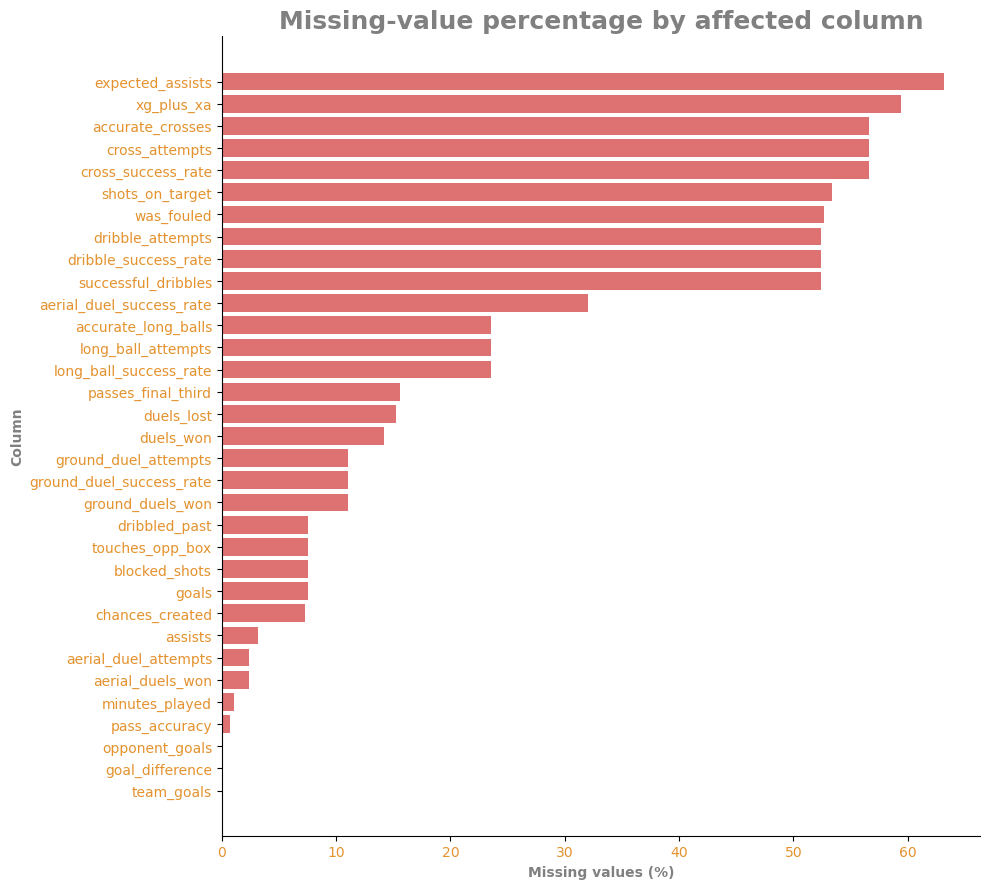

In [7]:
missing_table = (
    audit.loc[audit["missing_n"] > 0, ["column", "football_group", "missing_n", "missing_pct", "dtype", "unique_n", "zero_n"]]
    .sort_values(["missing_pct", "column"], ascending=[False, True])
    .reset_index(drop=True)
)
display(missing_table)

plt.figure(figsize=(10, 9))
plot_df = missing_table.sort_values("missing_pct")
plt.barh(plot_df["column"], plot_df["missing_pct"],color="#DE7272")
plt.xlabel("Missing values (%)",color="gray",weight="bold")
plt.ylabel("Column",color="gray",weight="bold")
plt.title("Missing-value percentage by affected column",color="gray",fontsize=18,weight="bold")
plt.xticks(color="#E4922E")
plt.yticks(color="#E4922E")
ax=plt.gca()
ax.spines[["top","right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 2.3 Missingness by goalkeeper vs outfield player

This is essential because some statistics are structurally different for goalkeepers.

In [8]:
affected = missing_table["column"].tolist()
gk_missing_rows = []

for col in affected:
    for gk_value, label in [(0, "Outfield"), (1, "Goalkeeper")]:
        sub = df.loc[df["is_goalkeeper"].eq(gk_value), col]
        gk_missing_rows.append({
            "column": col,
            "player_type": label,
            "missing_n": int(sub.isna().sum()),
            "missing_pct": round(float(sub.isna().mean() * 100), 3)
        })

gk_missing = pd.DataFrame(gk_missing_rows)
gk_missing_pivot = gk_missing.pivot(
    index="column", columns="player_type", values="missing_pct"
).reset_index()

display(gk_missing_pivot.sort_values("Goalkeeper", ascending=False))

player_type,column,Goalkeeper,Outfield
0,accurate_crosses,100.000,53.057
30,touches_opp_box,100.000,0.000
8,cross_attempts,100.000,53.057
9,cross_success_rate,100.000,53.057
12,dribbled_past,100.000,0.000
6,blocked_shots,99.916,0.000
17,goals,99.893,0.000
27,shots_on_target,99.346,49.584
28,successful_dribbles,97.839,48.687
10,dribble_attempts,97.839,48.687


## 2.4 Missingness by competition/provider context

For high-missing advanced metrics, whole competitions may have incomplete coverage. That is different from a true player value of zero.

In [9]:
HIGH_MISSING_THRESHOLD = 20
high_missing_cols = missing_table.loc[
    missing_table["missing_pct"] >= HIGH_MISSING_THRESHOLD, "column"
].tolist()

coverage_examples = []
for col in high_missing_cols:
    league_cov = (
        df.groupby("league_name")[col]
        .apply(lambda x: x.isna().mean() * 100)
        .sort_values(ascending=False)
        .head(5)
    )
    for league, pct in league_cov.items():
        coverage_examples.append({
            "column": col,
            "league_name": league,
            "missing_pct_in_league": round(float(pct), 2)
        })

coverage_table = pd.DataFrame(coverage_examples)
display(coverage_table)

,column,league_name,missing_pct_in_league
0,expected_assists,1. Division,100.00
1,expected_assists,Cup Final Stage,100.00
2,expected_assists,Qatar Stars League,100.00
3,expected_assists,Pro League,100.00
4,expected_assists,Primera División,100.00
5,xg_plus_xa,1. Division,100.00
6,xg_plus_xa,Cup Final Stage,100.00
7,xg_plus_xa,Qatar Stars League,100.00
8,xg_plus_xa,Pro League,100.00
9,xg_plus_xa,Primera División,100.00


by this table we can answer this question **(Are missing values concentrated in certain leagues?)**

# 3. Missing-value decision table

The decision table is deliberately explicit.

### Decision categories
- **Keep**: no missing problem.
- **Reconstruct**: the value can be recovered from other internally consistent match fields.
- **Fill 0 — no event**: null strongly represents absence of the recorded event.
- **Preserve NaN — undefined rate**: the percentage is undefined because attempts are zero.
- **Preserve NaN — structural/provider**: null is informative or likely means unavailable/not applicable.
- **Add missing indicator**: retain NaN for CatBoost and also expose that the information is absent.
- **Drop feature**: used only when a column is constant, an identifier, redundant for modeling, or otherwise unsuitable — not simply because it has many nulls.


In [10]:
# Evidence helpers used in the decision table
def nonmissing_min(col):
    return df[col].dropna().min() if df[col].notna().any() else np.nan

def all_missing_match(cols):
    base = df[cols[0]].isna()
    return all(df[c].isna().equals(base) for c in cols[1:])

evidence_checks = {
    "dribble_triplet_same_null_mask": all_missing_match(
        ["successful_dribbles", "dribble_attempts", "dribble_success_rate"]
    ),
    "cross_triplet_same_null_mask": all_missing_match(
        ["accurate_crosses", "cross_attempts", "cross_success_rate"]
    ),
    "long_ball_triplet_same_null_mask": all_missing_match(
        ["accurate_long_balls", "long_ball_attempts", "long_ball_success_rate"]
    ),
    "ground_duel_triplet_same_null_mask": all_missing_match(
        ["ground_duels_won", "ground_duel_attempts", "ground_duel_success_rate"]
    ),
    "pass_accuracy_missing_only_when_zero_passes": bool(
        (df.loc[df["pass_accuracy"].isna(), "total_passes"] == 0).all()
    ),
    "goal_missing_outfield": int(
        df.loc[df["is_goalkeeper"].eq(0), "goals"].isna().sum()
    ),
}
display(pd.Series(evidence_checks, name="result"))

dribble_triplet_same_null_mask                 True
cross_triplet_same_null_mask                   True
long_ball_triplet_same_null_mask               True
ground_duel_triplet_same_null_mask             True
pass_accuracy_missing_only_when_zero_passes    True
goal_missing_outfield                             0
Name: result, dtype: object

pass_accuracy is missing because no passes were attempted, so the percentage is mathematically undefined.--How many missing goals values exist among outfield players?

In [ ]:
# Explicit football/data decisions for every column that has missing values.
# These decisions are not based on a single missing-percentage threshold.

decision_map = {
    "team_goals": (
        "Reconstruct",
        "Missing rows can be recovered from home_score/away_score using is_home_team."
    ),
    "opponent_goals": (
        "Reconstruct",
        "Missing rows can be recovered from home_score/away_score using is_home_team."
    ),
    "goal_difference": (
        "Reconstruct",
        "Compute as team_goals - opponent_goals after reconstructing the two components."
    ),
    "minutes_played": (
        "Preserve NaN + indicator",
        "Minutes should normally exist, but missingness clusters strongly in specific competitions; do not invent minutes."
    ),
    "goals": (
        "Fill 0 — no event",
        "Outfield players have complete goal counts; almost all goalkeeper nulls correspond to no recorded goal, while scored goalkeeper goals are explicitly positive."
    ),
    "assists": (
        "Preserve NaN — structural/provider",
        "Goalkeepers contain both explicit zeros and nulls, so null cannot safely be assumed to mean zero."
    ),
    "shots_on_target": (
        "Preserve NaN — structural/provider",
        "Observed data contains genuine zeros as well as many nulls; null is not equivalent to zero."
    ),
    "blocked_shots": (
        "Fill 0 — no event",
        "Outfield values are complete; goalkeeper values are almost entirely null except positive recorded events, supporting no-event encoding."
    ),
    "expected_assists": (
        "Preserve NaN + indicator",
        "Very high missingness and competition-level coverage patterns suggest provider availability, not genuine zero xA."
    ),
    "xg_plus_xa": (
        "Preserve NaN + indicator",
        "Very high missingness and competition-level coverage patterns suggest provider availability, not genuine zero."
    ),
    "chances_created": (
        "Fill 0 — no event",
        "Outfield values are complete; goalkeeper nulls are dominant while positive goalkeeper events are explicitly recorded."
    ),
    "touches_opp_box": (
        "Preserve NaN — structural",
        "All goalkeeper rows are missing while outfield rows include true zeros; this is role-specific missingness."
    ),
    "successful_dribbles": (
        "Fill 0 — no attempt",
        "Shares the exact null mask with dribble_attempts; dribble_attempts has minimum observed value 1."
    ),
    "dribble_attempts": (
        "Fill 0 — no attempt",
        "Minimum non-null attempt count is 1, so null consistently represents no recorded attempt."
    ),
    "dribble_success_rate": (
        "Fill 0 with attempts=0 context",
        "The rate is undefined when there is no attempt; using 0 is safe only because dribble_attempts is simultaneously set to 0."
    ),
    "pass_accuracy": (
        "Preserve NaN — undefined rate",
        "Every missing pass_accuracy row has total_passes = 0; the percentage is mathematically undefined."
    ),
    "passes_final_third": (
        "Fill 0 — no event",
        "There are no observed zeros among non-null rows; minimum non-null count is 1."
    ),
    "accurate_crosses": (
        "Fill 0 — no attempt",
        "Shares exact null mask with cross_attempts; null corresponds to no cross attempt."
    ),
    "cross_attempts": (
        "Fill 0 — no attempt",
        "Minimum non-null attempt count is 1."
    ),
    "cross_success_rate": (
        "Fill 0 with attempts=0 context",
        "Rate is undefined with no crosses; paired zero attempts preserve interpretation."
    ),
    "accurate_long_balls": (
        "Fill 0 — no attempt",
        "Shares exact null mask with long_ball_attempts; null corresponds to no recorded attempt."
    ),
    "long_ball_attempts": (
        "Fill 0 — no attempt",
        "Minimum non-null attempt count is 1."
    ),
    "long_ball_success_rate": (
        "Fill 0 with attempts=0 context",
        "Rate is undefined with no long-ball attempts; paired zero attempts preserve interpretation."
    ),
    "dribbled_past": (
        "Preserve NaN — structural",
        "All goalkeeper rows are missing while outfield rows contain genuine zeros."
    ),
    "duels_won": (
        "Fill 0 — no event",
        "Minimum non-null value is 1; null acts as no duel won."
    ),
    "duels_lost": (
        "Fill 0 — no event",
        "Minimum non-null value is 1; null acts as no duel lost."
    ),
    "ground_duels_won": (
        "Fill 0 — no attempt",
        "Shares exact null mask with ground_duel_attempts; null corresponds to no ground duel attempt."
    ),
    "ground_duel_attempts": (
        "Fill 0 — no attempt",
        "Minimum non-null attempt count is 1."
    ),
    "ground_duel_success_rate": (
        "Fill 0 with attempts=0 context",
        "Rate is undefined with no attempts; paired zero attempts preserve interpretation."
    ),
    "aerial_duels_won": (
        "Preserve NaN — structural/provider",
        "Unlike ground duels, aerial_duel_attempts has explicit zeros and also nulls, so null is not safely equivalent to zero."
    ),
    "aerial_duel_attempts": (
        "Preserve NaN — structural/provider",
        "Explicit zero attempts exist as well as nulls; null likely represents unavailable/structural data."
    ),
    "aerial_duel_success_rate": (
        "Preserve NaN — undefined/provider",
        "Rate is undefined when attempts=0 and is also missing when the underlying aerial-duel data is unavailable."
    ),
    "was_fouled": (
        "Fill 0 — no event",
        "Minimum non-null count is 1, so null consistently represents no foul suffered."
    )
}

decision_rows = []
for _, r in missing_table.iterrows():
    col = r["column"]
    decision, reason = decision_map[col]
    decision_rows.append({
        "column": col,
        "football_group": r["football_group"],
        "missing_n": int(r["missing_n"]),
        "missing_pct": float(r["missing_pct"]),
        "decision": decision,
        "reason": reason
    })

missing_decisions = pd.DataFrame(decision_rows).sort_values(
    ["football_group", "missing_pct"], ascending=[True, False]
).reset_index(drop=True)

display(missing_decisions)

assert set(missing_decisions["column"]) == set(missing_table["column"]), (
    "Every missing column must have an explicit decision."
)

## 3.1 Apply only the approved missing-value decisions

We work on a copy and retain the raw data unchanged.

CatBoost can natively handle numeric NaN values, so true/structural/provider missingness does not need forced median imputation.

In [ ]:
data = df.copy()

# Reconstruct team-perspective result fields from complete home/away scores where needed.
m = data["team_goals"].isna()
data.loc[m, "team_goals"] = np.where(
    data.loc[m, "is_home_team"].eq(1),
    data.loc[m, "home_score"],
    data.loc[m, "away_score"]
)
data.loc[m, "opponent_goals"] = np.where(
    data.loc[m, "is_home_team"].eq(1),
    data.loc[m, "away_score"],
    data.loc[m, "home_score"]
)
data.loc[m, "goal_difference"] = (
    data.loc[m, "team_goals"] - data.loc[m, "opponent_goals"]
)
data.loc[m, "team_result"] = np.select(
    [
        data.loc[m, "goal_difference"] > 0,
        data.loc[m, "goal_difference"] < 0
    ],
    ["win", "loss"],
    default="draw"
)

ZERO_FILL = [
    "goals", "blocked_shots", "chances_created",
    "successful_dribbles", "dribble_attempts", "dribble_success_rate",
    "passes_final_third",
    "accurate_crosses", "cross_attempts", "cross_success_rate",
    "accurate_long_balls", "long_ball_attempts", "long_ball_success_rate",
    "duels_won", "duels_lost",
    "ground_duels_won", "ground_duel_attempts", "ground_duel_success_rate",
    "was_fouled"
]

data[ZERO_FILL] = data[ZERO_FILL].fillna(0)

# Missing indicators only where absence plausibly encodes provider/competition information.
for col in ["minutes_played", "expected_assists", "xg_plus_xa"]:
    data[f"{col}_missing"] = data[col].isna().astype("int8")

print("Missing values after rule-based treatment:")
remaining_missing = (
    data.isna().sum()
    .loc[lambda x: x > 0]
    .sort_values(ascending=False)
)
display(remaining_missing.to_frame("missing_n"))

# 4. Logical validity and outlier review

Football outliers are often genuine performance signals. A five-goal match, unusually high duel volume, or elite rating should **not** be removed merely for being statistically extreme.

Therefore:
1. check impossible values and internal contradictions;
2. flag statistical extremes for inspection;
3. keep valid football extremes;
4. remove/correct only demonstrable errors.

No automatic IQR/z-score deletion is used.

In [ ]:
rate_cols = [
    "dribble_success_rate", "pass_accuracy", "cross_success_rate",
    "long_ball_success_rate", "ground_duel_success_rate",
    "aerial_duel_success_rate"
]

count_pairs = [
    ("successful_dribbles", "dribble_attempts"),
    ("accurate_passes", "total_passes"),
    ("accurate_crosses", "cross_attempts"),
    ("accurate_long_balls", "long_ball_attempts"),
    ("ground_duels_won", "ground_duel_attempts"),
    ("aerial_duels_won", "aerial_duel_attempts")
]

validity_rows = []

for col in rate_cols:
    bad = ((data[col] < 0) | (data[col] > 100)).sum()
    validity_rows.append({
        "rule": f"{col} must be between 0 and 100",
        "violations": int(bad)
    })

for success, attempts in count_pairs:
    bad = (data[success] > data[attempts]).sum()
    validity_rows.append({
        "rule": f"{success} <= {attempts}",
        "violations": int(bad)
    })

# Non-negative event counts (goal_difference and target can validly be below zero / outside count logic).
excluded_from_nonnegative = {
    "player_rating", "goal_difference",
    "match_id", "league_id", "home_team_id", "away_team_id",
    "player_id", "team_id"
}
for col in data.select_dtypes(include=np.number).columns:
    if col not in excluded_from_nonnegative:
        bad = (data[col] < 0).sum()
        if bad:
            validity_rows.append({
                "rule": f"{col} should not be negative",
                "violations": int(bad)
            })

validity = pd.DataFrame(validity_rows)
display(validity)
print("Total logical violations:", validity["violations"].sum())

In [ ]:
# Quantile-based review only — these observations are NOT deleted.
review_cols = [
    "player_rating", "minutes_played", "goals", "assists", "shots_on_target",
    "touches", "total_passes", "tackles_won", "interceptions",
    "clearances", "recoveries", "duels_won", "aerial_duel_attempts"
]

outlier_review = data[review_cols].quantile(
    [0, 0.01, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999, 1.0]
).T
outlier_review.columns = [
    "min", "p01", "p25", "median", "p75", "p95", "p99", "p99.9", "max"
]
display(outlier_review)

print(
    "Policy: retain valid extremes. No row is removed merely for crossing an IQR or z-score threshold."
)

# 5. Exploratory Data Analysis

At this stage missingness, duplicates and validity have already been checked, so we can safely interpret distributions.

In [ ]:
target_stats = data[TARGET].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
display(target_stats.to_frame("player_rating"))

plt.figure(figsize=(9, 5))
plt.hist(data[TARGET], bins=45)
plt.xlabel("Player rating")
plt.ylabel("Player-match records")
plt.title("Distribution of player_rating")
plt.tight_layout()
plt.show()

In [ ]:
# Rating by goalkeeper status
rating_by_role = data.groupby("is_goalkeeper")[TARGET].agg(
    ["count", "mean", "median", "std", "min", "max"]
)
rating_by_role.index = rating_by_role.index.map({0: "Outfield", 1: "Goalkeeper"})
display(rating_by_role)

role_data = [
    data.loc[data["is_goalkeeper"].eq(0), TARGET],
    data.loc[data["is_goalkeeper"].eq(1), TARGET]
]
plt.figure(figsize=(7, 5))
plt.boxplot(role_data, labels=["Outfield", "Goalkeeper"], showfliers=False)
plt.ylabel("Player rating")
plt.title("Rating distribution by player type")
plt.tight_layout()
plt.show()

In [ ]:
# Match result and rating
result_summary = (
    data.groupby("team_result")[TARGET]
    .agg(["count", "mean", "median", "std"])
    .sort_values("mean", ascending=False)
)
display(result_summary)

plt.figure(figsize=(7, 5))
ordered_results = [x for x in ["win", "draw", "loss"] if x in data["team_result"].unique()]
plt.bar(
    ordered_results,
    [data.loc[data["team_result"].eq(r), TARGET].mean() for r in ordered_results]
)
plt.ylabel("Mean player rating")
plt.xlabel("Team result")
plt.title("Average player rating by team result")
plt.tight_layout()
plt.show()

In [ ]:
# Same-match performance examples.
# Hexbin is used to keep 173k observations readable.
plt.figure(figsize=(8, 5))
valid_minutes = data["minutes_played"].notna()
plt.hexbin(
    data.loc[valid_minutes, "minutes_played"],
    data.loc[valid_minutes, TARGET],
    gridsize=45,
    mincnt=1
)
plt.xlabel("Minutes played")
plt.ylabel("Player rating")
plt.title("Minutes played vs player rating")
plt.tight_layout()
plt.show()

goal_summary = data.groupby("goals")[TARGET].agg(["count", "mean", "median"]).reset_index()
display(goal_summary)

In [ ]:
# Numeric correlation with the target is descriptive only; it does not establish causality.
numeric_corr = (
    data.select_dtypes(include=np.number)
    .corr(numeric_only=True)[TARGET]
    .drop(TARGET)
    .dropna()
    .sort_values(key=lambda s: s.abs(), ascending=False)
)

display(numeric_corr.head(20).to_frame("correlation_with_player_rating"))

top_corr = numeric_corr.head(15).sort_values()
plt.figure(figsize=(9, 6))
plt.barh(top_corr.index, top_corr.values)
plt.xlabel("Pearson correlation with player_rating")
plt.title("Top numeric correlations with the target")
plt.tight_layout()
plt.show()

# 6. Feature selection and leakage/redundancy audit

The primary model is intended to estimate a player's **same-match rating from match performance**.

We therefore exclude:
- direct row/player/team identifiers that encourage memorization;
- names duplicating those identifiers;
- the constant season field;
- raw `match_date` after deriving simple date features;
- raw home/away score columns because team-perspective score variables already encode the relevant match result.

We keep league/country context because rating scales/data coverage can vary across competitions.

This is **not** pre-match forecasting. If a pre-match forecast were required, all same-match performance statistics would have to be removed.

In [ ]:
# Date features
data["match_month"] = data["match_date"].dt.month
data["match_dayofweek"] = data["match_date"].dt.dayofweek
data["match_day"] = data["match_date"].dt.day

DROP_FROM_MODEL = [
    TARGET,
    "match_id",
    "league_id",
    "home_team_id", "home_team_name",
    "away_team_id", "away_team_name",
    "player_id", "player_name",
    "team_id", "team_name",
    "parent_league_season",
    "match_date",
    "home_score", "away_score"
]

FEATURES = [c for c in data.columns if c not in DROP_FROM_MODEL]
CATEGORICAL_FEATURES = [
    c for c in FEATURES if data[c].dtype == "object"
]

feature_decisions = pd.DataFrame({
    "column": df.columns,
    "model_action": [
        "Target" if c == TARGET
        else "Exclude from model" if c in DROP_FROM_MODEL
        else "Keep"
        for c in df.columns
    ],
    "reason": [
        "Prediction target"
        if c == TARGET else
        "High-cardinality identifier/name; avoid player/team/match memorization"
        if c in {
            "match_id", "home_team_id", "home_team_name", "away_team_id",
            "away_team_name", "player_id", "player_name", "team_id", "team_name"
        } else
        "ID duplicates league_name; use readable league context instead"
        if c == "league_id" else
        "Constant in this dataset; no predictive information"
        if c == "parent_league_season" else
        "Converted to month/day/day-of-week features"
        if c == "match_date" else
        "Redundant with team-perspective goals plus is_home_team"
        if c in {"home_score", "away_score"} else
        "Retained after data-quality review"
        for c in df.columns
    ]
})

display(feature_decisions)
print("Model feature count:", len(FEATURES))
print("Categorical features:", CATEGORICAL_FEATURES)

# 7. Time-aware train / validation / test split

A random row split could put earlier and later matches from the same football environment on both sides of the evaluation.

The main evaluation therefore uses chronological match dates:
- first ~70% of unique match dates → training
- next ~15% → validation
- final ~15% → test

All observations from the same date stay in the same period.

In [ ]:
unique_dates = np.array(sorted(data["match_date"].dt.normalize().dropna().unique()))

cut_70 = pd.Timestamp(unique_dates[int(len(unique_dates) * 0.70)])
cut_85 = pd.Timestamp(unique_dates[int(len(unique_dates) * 0.85)])

train = data.loc[data["match_date"] < cut_70].copy()
valid = data.loc[
    (data["match_date"] >= cut_70) & (data["match_date"] < cut_85)
].copy()
test = data.loc[data["match_date"] >= cut_85].copy()

split_summary = pd.DataFrame({
    "split": ["Train", "Validation", "Test"],
    "rows": [len(train), len(valid), len(test)],
    "min_date": [
        train["match_date"].min(),
        valid["match_date"].min(),
        test["match_date"].min()
    ],
    "max_date": [
        train["match_date"].max(),
        valid["match_date"].max(),
        test["match_date"].max()
    ],
    "target_mean": [
        train[TARGET].mean(),
        valid[TARGET].mean(),
        test[TARGET].mean()
    ]
})
display(split_summary)

assert train["match_date"].max() < valid["match_date"].min()
assert valid["match_date"].max() < test["match_date"].min()

# 8. Baseline model

Before machine learning, predict the training-set mean rating for every test observation.

A useful model should substantially improve on this baseline.

In [ ]:
def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

baseline_pred = np.full(len(test), train[TARGET].mean())
baseline_metrics = regression_metrics(test[TARGET], baseline_pred)

display(pd.DataFrame(
    [{"model": "Mean baseline", **baseline_metrics}]
).set_index("model"))

# 9. CatBoost regression

Why CatBoost is appropriate here:
- strong performance on tabular data;
- nonlinear interactions between football actions;
- native handling of categorical variables;
- native handling of numeric NaNs;
- relatively robust to extreme values;
- built-in feature importance and SHAP support.

No standardization is required for tree-based CatBoost.

In [ ]:
X_train = train[FEATURES].copy()
y_train = train[TARGET].copy()

X_valid = valid[FEATURES].copy()
y_valid = valid[TARGET].copy()

X_test = test[FEATURES].copy()
y_test = test[TARGET].copy()

# CatBoost categorical columns cannot contain NaN strings.
for col in CATEGORICAL_FEATURES:
    X_train[col] = X_train[col].fillna("__MISSING__").astype(str)
    X_valid[col] = X_valid[col].fillna("__MISSING__").astype(str)
    X_test[col] = X_test[col].fillna("__MISSING__").astype(str)

model = CatBoostRegressor(
    iterations=800,
    depth=8,
    learning_rate=0.07,
    loss_function="RMSE",
    eval_metric="MAE",
    random_seed=RANDOM_SEED,
    l2_leaf_reg=5,
    random_strength=0.5,
    verbose=100,
    allow_writing_files=False,
    thread_count=-1
)

model.fit(
    X_train, y_train,
    cat_features=CATEGORICAL_FEATURES,
    eval_set=(X_valid, y_valid),
    early_stopping_rounds=80,
    use_best_model=True
)

print("Best iteration:", model.get_best_iteration())

# 10. Model evaluation

Primary metric: **MAE** because it is directly interpretable in rating points.

Also report:
- **RMSE** — penalizes large errors more strongly;
- **R²** — proportion of target variance explained relative to a constant predictor.

In [ ]:
valid_pred = model.predict(X_valid)
test_pred = model.predict(X_test)

valid_metrics = regression_metrics(y_valid, valid_pred)
test_metrics = regression_metrics(y_test, test_pred)

metrics_table = pd.DataFrame([
    {"model": "Mean baseline (test)", **baseline_metrics},
    {"model": "CatBoost validation", **valid_metrics},
    {"model": "CatBoost test", **test_metrics}
]).set_index("model")

display(metrics_table)

improvement_mae = 100 * (
    baseline_metrics["MAE"] - test_metrics["MAE"]
) / baseline_metrics["MAE"]

print(f"MAE improvement over mean baseline: {improvement_mae:.1f}%")
print(
    f"Non-technical interpretation: on the held-out future period, "
    f"the model misses the player rating by about {test_metrics['MAE']:.3f} "
    f"rating points on average."
)

## 10.1 Subgroup evaluation

A good overall metric can hide weak performance for particular football roles or rating ranges.

In [ ]:
test_eval = test[
    ["player_name", "league_name", "is_goalkeeper", "minutes_played", TARGET]
].copy()
test_eval["prediction"] = test_pred
test_eval["residual"] = test_eval[TARGET] - test_eval["prediction"]
test_eval["abs_error"] = test_eval["residual"].abs()

def subgroup_metrics(frame, group_col):
    rows = []
    for group, sub in frame.groupby(group_col, dropna=False):
        if len(sub) < 2:
            continue
        rows.append({
            group_col: group,
            "n": len(sub),
            "MAE": mean_absolute_error(sub[TARGET], sub["prediction"]),
            "RMSE": np.sqrt(mean_squared_error(sub[TARGET], sub["prediction"])),
            "R2": r2_score(sub[TARGET], sub["prediction"])
        })
    return pd.DataFrame(rows)

test_eval["player_type"] = np.where(
    test_eval["is_goalkeeper"].eq(1), "Goalkeeper", "Outfield"
)
display(subgroup_metrics(test_eval, "player_type"))

test_eval["minutes_band"] = pd.cut(
    test_eval["minutes_played"],
    bins=[-np.inf, 30, 60, 89, np.inf],
    labels=["<=30", "31-60", "61-89", "90+"]
)
display(subgroup_metrics(test_eval, "minutes_band"))

test_eval["rating_band"] = pd.cut(
    test_eval[TARGET],
    bins=[-np.inf, 6, 7, 8, 9, np.inf],
    labels=["<6", "6-7", "7-8", "8-9", "9+"],
    right=False
)
display(subgroup_metrics(test_eval, "rating_band"))

# 11. Feature importance

Feature importance describes what the fitted model relies on most. It does not prove causal influence.

In [ ]:
importance = pd.DataFrame({
    "feature": FEATURES,
    "importance": model.get_feature_importance()
}).sort_values("importance", ascending=False)

display(importance.head(25))

top_imp = importance.head(20).sort_values("importance")
plt.figure(figsize=(9, 7))
plt.barh(top_imp["feature"], top_imp["importance"])
plt.xlabel("CatBoost feature importance")
plt.title("Top 20 model features")
plt.tight_layout()
plt.show()

## 11.1 SHAP directionality on a sample

CatBoost SHAP values help answer not just *which* features matter, but whether a feature pushed an individual prediction higher or lower.

To keep the notebook practical, SHAP is computed on a reproducible sample of the test set.

In [ ]:
SHAP_SAMPLE_N = min(2000, len(X_test))
shap_sample = X_test.sample(SHAP_SAMPLE_N, random_state=RANDOM_SEED)
shap_pool = Pool(shap_sample, cat_features=CATEGORICAL_FEATURES)

shap_values = model.get_feature_importance(
    shap_pool,
    type="ShapValues"
)

# Last column is the expected value / baseline.
mean_abs_shap = np.abs(shap_values[:, :-1]).mean(axis=0)

shap_importance = pd.DataFrame({
    "feature": FEATURES,
    "mean_abs_shap": mean_abs_shap
}).sort_values("mean_abs_shap", ascending=False)

display(shap_importance.head(20))

# 12. Residual analysis

Residual = actual rating − predicted rating.

- positive residual: model under-predicted the player;
- negative residual: model over-predicted the player.

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(test_eval["residual"], bins=50)
plt.xlabel("Residual (actual - predicted)")
plt.ylabel("Player-match records")
plt.title("Residual distribution on the held-out test period")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 6))
plt.hexbin(
    test_eval["prediction"],
    test_eval[TARGET],
    gridsize=45,
    mincnt=1
)
lims = [
    min(test_eval["prediction"].min(), test_eval[TARGET].min()),
    max(test_eval["prediction"].max(), test_eval[TARGET].max())
]
plt.plot(lims, lims, linestyle="--")
plt.xlabel("Predicted rating")
plt.ylabel("Actual rating")
plt.title("Actual vs predicted player rating")
plt.tight_layout()
plt.show()

In [ ]:
# Largest errors are inspected, not automatically deleted.
largest_errors = test_eval.sort_values("abs_error", ascending=False).head(30)
display(largest_errors)

print("Mean residual:", test_eval["residual"].mean())
print("Median absolute error:", test_eval["abs_error"].median())
print("95th percentile absolute error:", test_eval["abs_error"].quantile(0.95))

# 13. Football-oriented technical summary

Run the next cell after the model completes. It generates a concise summary from the actual measured results rather than hard-coding conclusions.

In [ ]:
top_features = importance.head(10)["feature"].tolist()

summary_text = f'''
TECHNICAL SUMMARY
-----------------
Rows analysed: {len(data):,}
Original columns: {df_raw.shape[1]}
Target: {TARGET}
Duplicate player-match rows: {int(df.duplicated(["match_id", "player_id"]).sum())}
Train period: {train["match_date"].min().date()} to {train["match_date"].max().date()}
Validation period: {valid["match_date"].min().date()} to {valid["match_date"].max().date()}
Test period: {test["match_date"].min().date()} to {test["match_date"].max().date()}

Mean-baseline test MAE: {baseline_metrics["MAE"]:.4f}
CatBoost test MAE: {test_metrics["MAE"]:.4f}
CatBoost test RMSE: {test_metrics["RMSE"]:.4f}
CatBoost test R²: {test_metrics["R2"]:.4f}

Top model features:
{", ".join(top_features)}

OUTLIER POLICY
--------------
No legitimate statistical extreme was removed merely for being unusual.
Only logical impossibilities would justify correction/removal.

MISSING-VALUE POLICY
--------------------
No universal median/zero rule was used.
Nulls were treated according to football meaning and provider/role patterns.
CatBoost retained genuine numeric NaNs where appropriate.
'''
print(summary_text)

# 14. Non-technical football summary

The cell below translates the measured test performance into language suitable for a coach, scout or sporting director.

In [ ]:
print(
    f"The model was tested only on later matches that were not used for training. "
    f"On those matches, its average error was {test_metrics['MAE']:.2f} rating points, "
    f"compared with {baseline_metrics['MAE']:.2f} for a simple average-rating prediction. "
    f"It explained about {test_metrics['R2']*100:.1f}% of the variation in ratings in the held-out period.\n\n"
    f"The most influential variables in this fitted model were: "
    f"{', '.join(top_features[:8])}. "
    f"These importances describe the model's rating reconstruction process; they do not prove that a statistic causes a rating change.\n\n"
    f"Missing values were not treated as one generic problem. "
    f"'No event', undefined percentages, goalkeeper-specific missingness and competition/provider gaps "
    f"were handled separately. Genuine extreme football performances were retained."
)

# 15. Limitations and next steps

1. **This is a rating-estimation model, not a pre-match forecast.** Same-match actions are included.
2. The dataset covers a relatively short window (January–June 2025); model stability should be re-tested on later seasons.
3. `player_rating` may itself be generated by a provider algorithm partly from the same event statistics. High predictive accuracy can therefore reflect successful reconstruction of that rating logic.
4. Competition/provider missingness can carry information. The notebook preserves this rather than pretending every null equals zero.
5. Position is represented mainly through `is_goalkeeper`; richer position labels (CB, FB, DM, AM, winger, striker) would improve subgroup analysis if available.
6. For deployment, the exact preprocessing and feature list used here must be applied identically to future data.

## Optional: save key analytical outputs

These files make the audit and modeling decisions easy to review outside the notebook.

In [ ]:
OUTPUT_DIR = Path("football_rating_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

audit.to_csv(OUTPUT_DIR / "all_63_columns_audit.csv", index=False)
missing_decisions.to_csv(OUTPUT_DIR / "missing_value_decisions.csv", index=False)
feature_decisions.to_csv(OUTPUT_DIR / "feature_selection_decisions.csv", index=False)
metrics_table.to_csv(OUTPUT_DIR / "model_metrics.csv")
importance.to_csv(OUTPUT_DIR / "catboost_feature_importance.csv", index=False)
test_eval.to_csv(OUTPUT_DIR / "test_predictions_and_residuals.csv", index=False)

print("Saved analytical outputs to:", OUTPUT_DIR.resolve())